# MotionProof AI
## Deliverable 4: Extended Evaluation

This notebook presents the four D4 analyses and re-checks their key numbers. The analyses themselves are run from the terminal so they can be reproduced without Jupyter:

```
python -m src.experiments.run_motion_thresholds     # Phase 1 (needs data/processed/val and test)
python -m src.experiments.run_participant_analysis  # Phase 2
python -m src.experiments.run_bootstrap             # Phase 3
python -m src.experiments.run_failure_cases         # Phase 4 (needs data/processed/test)
```

Nothing here trains a model or changes a frozen file. Motion edges and thresholds are selected on validation participants S11–S12 only; test participants S13–S15 are scored once. The success criteria were written in `configs/experiments/d4_motion_thresholds.json` before Phase 1 was run.

In [1]:
from pathlib import Path
import json
import sys

import joblib
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.experiments import verify_frozen
from src.experiments.common import VALIDATION_INPUTS, load_config
from src.experiments.d4_common import POLICIES, load_test_windows
from src.experiments.motion_aware import assign_levels, motion_edges, select_global, select_motion_aware, metrics
from src.experiments.run_bootstrap import bootstrap, interval, point
from src.experiments.run_fp_reduction import CALIBRATOR, KEYS, VAL_DECISIONS, frozen_learned

R = ROOT / "results" / "experiments"
pd.set_option("display.width", 160)
count, problems = verify_frozen.check()
assert not problems
print(f"All {count} frozen D2/D3 artifacts unchanged.")

All 15 frozen D2/D3 artifacts unchanged.


## Phase 1: Motion-aware operating points

**Question.** Can motion-aware operating points reduce false alarms without significantly sacrificing failure detection?

**Candidates.** (1) the frozen D2 agent; (2) the D3 global calibrated veto, which keeps an agent flag only if the calibrated probability is at least $\tau$; (3) a motion-aware veto with one threshold per motion level (low, moderate, high: tertiles of validation motion intensity).

**Success criteria, fixed before running:** C1, validation FPR at least 1 point lower than the global veto; C2, in leave-one-participant-out inside validation, lower held-out FPR than the global veto in both folds with recall within 5 points of the frozen agent; C3, test confirmation (reported, not used for selection).

In [2]:
cfg = load_config("d4_motion_thresholds")
display(pd.Series(cfg["success_criteria"]).to_frame("criterion"))

# re-run the validation selection in memory and compare with the saved result
platt = joblib.load(CALIBRATOR)
val = (pd.read_csv(VALIDATION_INPUTS).sort_values(KEYS)
       .merge(frozen_learned(VAL_DECISIONS)[KEYS + ["predicted_unreliable", "investigations_used"]], on=KEYS)
       .merge(pd.read_csv(R / "d4_motion_thresholds/motion_intensity_validation.csv"), on=KEYS))
assert set(val.subject) == {11, 12}
y, flags, p = val.unreliable_target.to_numpy(), val.predicted_unreliable.to_numpy(), platt.predict(val.unreliable_probability.to_numpy())
edges = motion_edges(val.motion_intensity_g)
levels = assign_levels(val.motion_intensity_g, edges)
floor = metrics(y, flags, val.investigations_used.to_numpy())["recall"] - 0.05
g, m = select_global(y, flags, p, floor), select_motion_aware(y, flags, p, levels, floor)

saved = json.loads((R / "d4_motion_thresholds/selection.json").read_text())
assert g == saved["global_veto_tau"] and list(m) == list(saved["motion_aware_taus"].values())
assert np.allclose(edges, saved["motion_edges_g"])
print("Validation selection reproduced.")
print("Motion edges (g):", np.round(edges, 3), "| global tau:", g, "| motion-aware taus (low, moderate, high):", m)
display(pd.Series(saved["criteria"]).to_frame("result"))

,criterion
C1_validation_gain,selected motion-aware veto has validation FPR ...
C2_out_of_participant,leave-one-participant-out inside validation: s...
decision,motion-aware operating points are supported on...
C3_test_confirmation,"reported once, not used for selection: motion-..."


Validation selection reproduced.
Motion edges (g): [0.048 0.221] | global tau: 0.26 | motion-aware taus (low, moderate, high): (0.56, 0.23, 0.2)


,result
C1_validation_gain,True
C2_out_of_participant,False
motion_aware_supported,False
C3_test_confirmation,False


**Validation comparison**

,candidate,recall,false_positive_rate,f1,precision
0,Frozen agent (D2),0.8569,0.3994,0.6481,0.5211
1,Global calibrated veto,0.8128,0.3667,0.6410,0.5292
2,Motion-aware veto,0.8079,0.3486,0.6476,0.5403


**Test comparison**

,candidate,recall,false_positive_rate,f1,precision
0,Frozen agent (D2),0.8814,0.3961,0.4061,0.2638
1,Global calibrated veto,0.8093,0.3541,0.4038,0.2690
2,Motion-aware veto,0.7988,0.3516,0.4012,0.2678


**Leave-one-participant-out inside validation**

,selected_on,evaluated_on,candidate,recall,false_positive_rate,heldout_recall_floor,fold_pass
0,S11,S12,Frozen agent (D2),0.8162,0.3499,0.7662,False
1,S11,S12,Global calibrated veto,0.7894,0.3215,0.7662,False
2,S11,S12,Motion-aware veto,0.7605,0.3204,0.7662,False
3,S12,S11,Frozen agent (D2),0.8952,0.4412,0.8452,False
4,S12,S11,Global calibrated veto,0.8231,0.4048,0.8452,False
5,S12,S11,Motion-aware veto,0.7626,0.3923,0.8452,False


**Test results by motion level**

,candidate,motion_level,windows,unreliable_rate,recall,false_positive_rate
0,Frozen agent (D2),low,4636,0.051,0.726,0.083
1,Frozen agent (D2),moderate,4821,0.129,0.830,0.494
2,Frozen agent (D2),high,3550,0.266,0.954,0.767
3,Global calibrated veto,low,4636,0.051,0.612,0.064
4,Global calibrated veto,moderate,4821,0.129,0.735,0.433
5,Global calibrated veto,high,3550,0.266,0.908,0.718
6,Motion-aware veto,low,4636,0.051,0.228,0.008
7,Motion-aware veto,moderate,4821,0.129,0.785,0.462
8,Motion-aware veto,high,3550,0.266,0.951,0.754


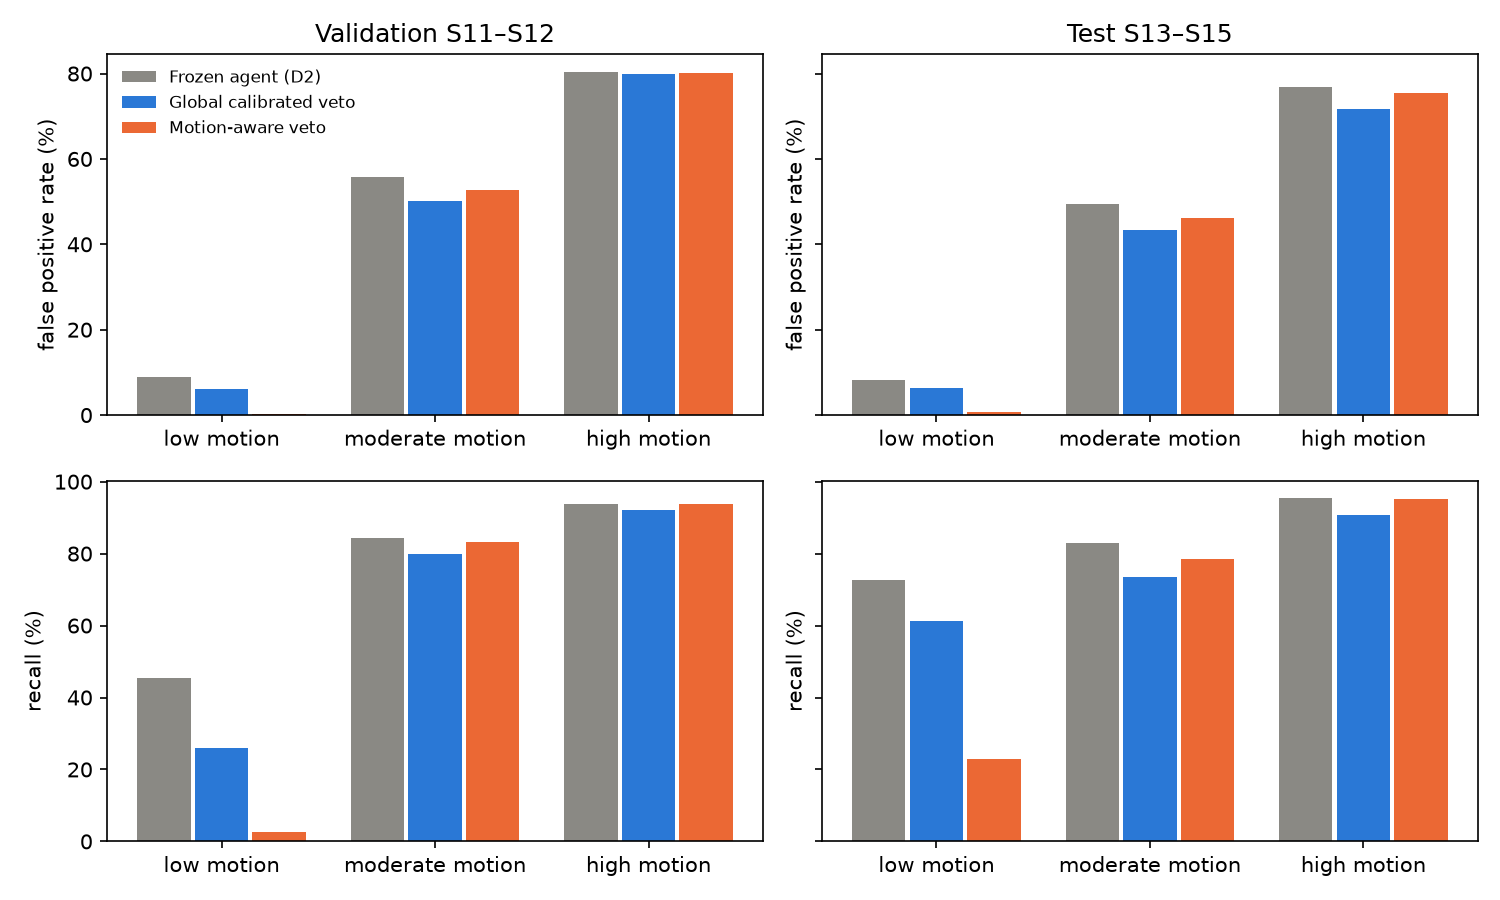

In [3]:
cols = ["candidate", "recall", "false_positive_rate", "f1", "precision"]
for name in ("validation_comparison", "test_comparison"):
    display(Markdown(f"**{name.replace('_', ' ').capitalize()}**"))
    display(pd.read_csv(R / f"d4_motion_thresholds/{name}.csv")[cols].round(4))
display(Markdown("**Leave-one-participant-out inside validation**"))
display(pd.read_csv(R / "d4_motion_thresholds/validation_loso_folds.csv")[
    ["selected_on", "evaluated_on", "candidate", "recall", "false_positive_rate", "heldout_recall_floor", "fold_pass"]].round(4))
display(Markdown("**Test results by motion level**"))
display(pd.read_csv(R / "d4_motion_thresholds/test_per_level.csv")[
    ["candidate", "motion_level", "windows", "unreliable_rate", "recall", "false_positive_rate"]].round(3))
display(Image(str(R / "d4_motion_thresholds/per_level_comparison.png"), width=800))

**Finding (negative).** C1 passed, but C2 failed in both folds and C3 failed, so motion-aware operating points are **not supported**. The search lowered false alarms mainly by vetoing flags in *low*-motion windows, which cut low-motion recall sharply (72.6% to 22.8% on test). It could not lower high-motion false alarms, because there the classifier probability barely separates failures from good windows (Phase 2).

## Phase 2: Participant-wise results

,participant,policy,cnn_mae_bpm,unreliable_rate,recall,f1,false_positive_rate,average_investigations
0,S13,No Investigation,4.782,0.113,0.830,0.362,0.352,0.000
1,S13,Fixed Rule,4.782,0.113,0.840,0.392,0.313,1.064
2,S13,Learned Fitted Q,4.782,0.113,0.942,0.385,0.379,0.932
3,S13,Global calibrated veto,4.782,0.113,0.909,0.393,0.348,0.932
4,S13,Motion-aware veto,4.782,0.113,0.882,0.383,0.349,0.932
5,S14,No Investigation,5.385,0.130,0.716,0.294,0.468,0.000
6,S14,Fixed Rule,5.385,0.130,0.764,0.315,0.460,1.315
7,S14,Learned Fitted Q,5.385,0.130,0.826,0.326,0.482,0.886
8,S14,Global calibrated veto,5.385,0.130,0.790,0.323,0.461,0.886
9,S14,Motion-aware veto,5.385,0.130,0.747,0.325,0.425,0.886


**Classifier AUC within each motion level**

motion_level,low,moderate,high
participant,,,
All (pooled),0.892,0.636,0.534
S13,0.924,0.763,0.584
S14,0.857,0.547,0.503
S15,0.952,0.777,0.650


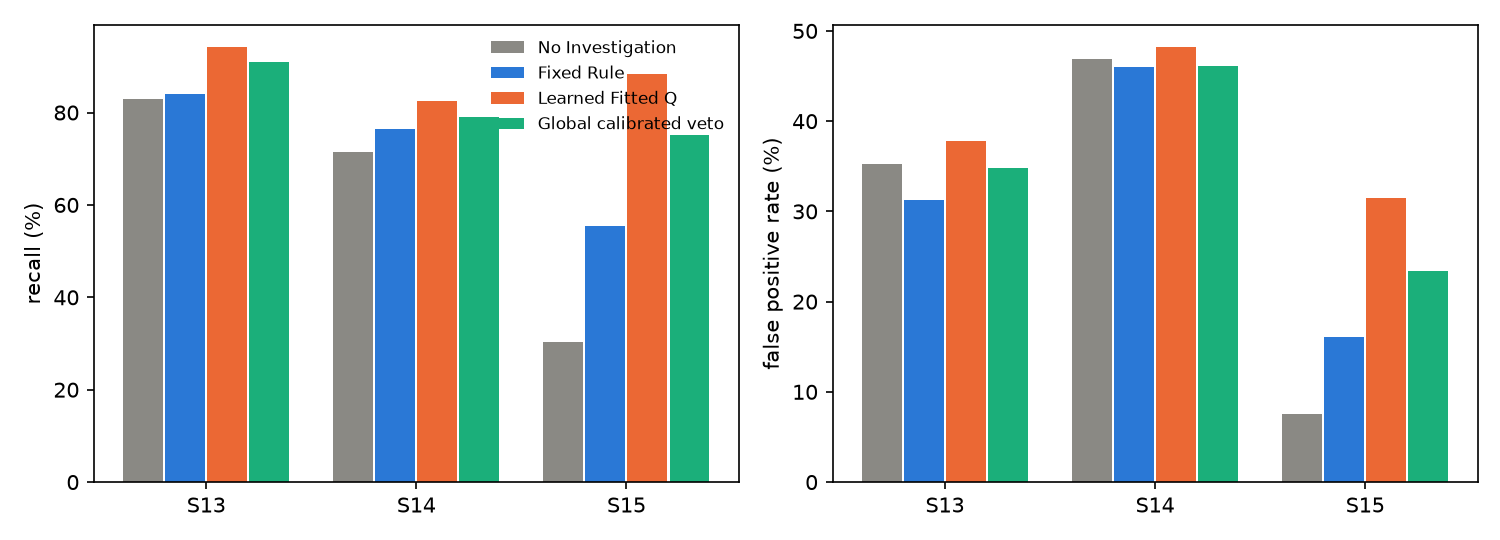

In [4]:
pa = pd.read_csv(R / "d4_participant_analysis/participant_metrics.csv")
display(pa[["participant", "policy", "cnn_mae_bpm", "unreliable_rate", "recall", "f1", "false_positive_rate",
            "average_investigations"]].round(3))
display(Markdown("**Classifier AUC within each motion level**"))
auc = pd.read_csv(R / "d4_participant_analysis/classifier_auc_by_motion.csv")
display(auc.pivot(index="participant", columns="motion_level", values="classifier_auc")[["low", "moderate", "high"]].round(3))
display(Image(str(R / "d4_participant_analysis/participant_comparison.png"), width=800))

## Phase 3: Uncertainty (moving-block bootstrap)

Blocks of 30 consecutive windows (about 68 s of signal) are resampled within each participant, 2,000 times; all policies are scored on the same resamples so differences are paired. The intervals describe variation within these three participants' recordings, not the wider population.

Learned − Fixed recall: 17.8 points, 95% CI [14.9, 20.7] (reproduced)


,comparison,metric,estimate,ci_low,ci_high,excludes_zero
20,Learned Fitted Q − Fixed Rule,recall,17.8,14.9,20.7,True
21,Learned Fitted Q − Fixed Rule,false_positive_rate,7.6,6.2,9.0,True
22,Learned Fitted Q − Fixed Rule,f1,2.5,1.2,3.8,True
23,Learned Fitted Q − Fixed Rule,precision,0.2,-0.7,1.2,False
24,Learned Fitted Q − No Investigation,recall,29.4,24.5,34.2,True
25,Learned Fitted Q − No Investigation,false_positive_rate,8.4,6.6,10.2,True
26,Learned Fitted Q − No Investigation,f1,7.3,5.1,9.7,True
27,Learned Fitted Q − No Investigation,precision,3.1,1.6,4.7,True
28,Global calibrated veto − Learned Fitted Q,recall,-7.2,-8.9,-5.6,True
29,Global calibrated veto − Learned Fitted Q,false_positive_rate,-4.2,-4.7,-3.7,True


**Sensitivity to block length (Learned − Fixed recall)**

,block_windows,estimate,ci_low,ci_high
0,15,0.1779,0.1510,0.2041
20,30,0.1779,0.1494,0.2067
40,60,0.1779,0.1503,0.2069
60,120,0.1779,0.1442,0.2100


**Per participant**

,participant,comparison,metric,estimate,ci_low,ci_high,excludes_zero
0,S13,Learned Fitted Q − Fixed Rule,recall,0.1023,0.0658,0.1466,True
1,S13,Learned Fitted Q − Fixed Rule,false_positive_rate,0.0657,0.0368,0.0911,True
2,S13,Learned Fitted Q − Fixed Rule,f1,-0.0075,-0.0270,0.0136,False
15,S14,Learned Fitted Q − Fixed Rule,recall,0.0621,0.0237,0.1011,True
16,S14,Learned Fitted Q − Fixed Rule,false_positive_rate,0.0221,-0.0028,0.0463,False
17,S14,Learned Fitted Q − Fixed Rule,f1,0.0114,-0.0034,0.0256,False
30,S15,Learned Fitted Q − Fixed Rule,recall,0.3286,0.2822,0.3763,True
31,S15,Learned Fitted Q − Fixed Rule,false_positive_rate,0.1537,0.1293,0.1775,True
32,S15,Learned Fitted Q − Fixed Rule,f1,0.0470,0.0141,0.0816,True


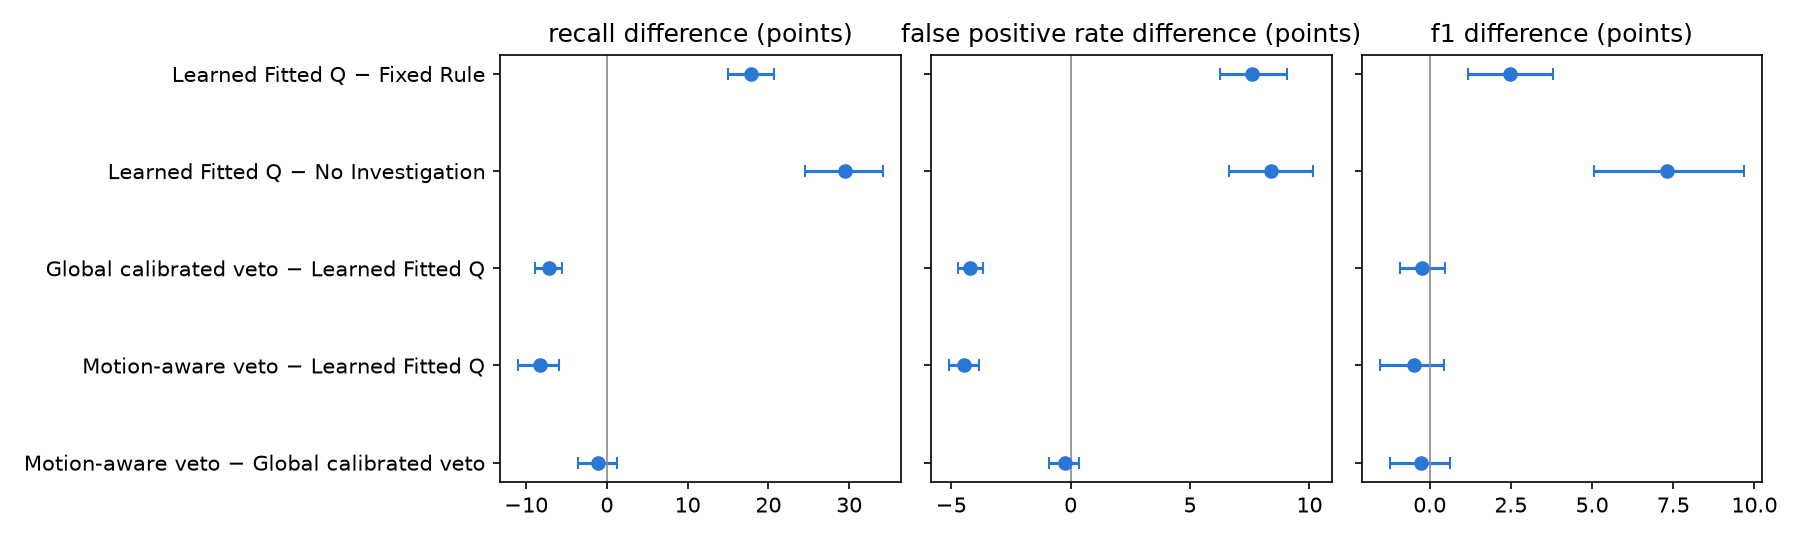

In [5]:
frame = load_test_windows()
bcfg = load_config("d4_evaluation")["bootstrap"]
boot = bootstrap(frame, bcfg["primary_block_windows"], bcfg["replicates"], bcfg["seed"])
diff = boot["Learned Fitted Q"]["recall"] - boot["Fixed Rule"]["recall"]
lo, hi = interval(diff, 0.95)
saved = pd.read_csv(R / "d4_bootstrap/paired_differences.csv")
row = saved[(saved.block_windows == 30) & (saved.comparison == "Learned Fitted Q − Fixed Rule") & (saved.metric == "recall")].iloc[0]
assert np.isclose(lo, row.ci_low) and np.isclose(hi, row.ci_high)
print(f"Learned − Fixed recall: {100*row.estimate:.1f} points, 95% CI [{100*lo:.1f}, {100*hi:.1f}] (reproduced)")

prim = saved[saved.block_windows == 30].copy()
for c in ("estimate", "ci_low", "ci_high"):
    prim[c] = (100 * prim[c]).round(1)
display(prim[["comparison", "metric", "estimate", "ci_low", "ci_high", "excludes_zero"]])
display(Markdown("**Sensitivity to block length (Learned − Fixed recall)**"))
display(saved[(saved.comparison == "Learned Fitted Q − Fixed Rule") & (saved.metric == "recall")][
    ["block_windows", "estimate", "ci_low", "ci_high"]].round(4))
display(Markdown("**Per participant**"))
pp = pd.read_csv(R / "d4_bootstrap/paired_differences_by_participant.csv")
display(pp[pp.comparison == "Learned Fitted Q − Fixed Rule"].round(4))
display(Image(str(R / "d4_bootstrap/paired_differences.png"), width=900))

## Phase 4: Failure cases

,category,windows,median_p,median_abs_error_bpm,median_motion_g,share_high_motion,median_spectral_disagreement_bpm,median_autocorrelation,median_hr_jump_bpm,mean_checks,share_decided_without_checks
0,caught_failure,1590,0.604,14.379,0.238,0.567,21.814,0.228,3.644,1.129,0.397
1,correct_accept,6766,0.110,2.709,0.030,0.090,3.242,0.523,1.882,0.890,0.335
2,false_alarm,4437,0.611,4.063,0.209,0.451,11.563,0.273,2.654,0.973,0.492
3,missed_failure,214,0.283,11.787,0.075,0.201,8.707,0.208,3.257,1.528,0.079


**Where investigations changed the decision relative to the probability-only rule (p ≥ 0.5)**

,change_type,windows,median_p,median_abs_error_bpm,median_motion_g,median_spectral_disagreement_bpm
0,harmful: missed a failure p>=0.5 would catch,45,0.627,13.329,0.162,11.543
1,harmful: raised a false alarm p<0.5 would avoid,1580,0.339,4.564,0.186,18.333
2,helpful: avoided a false alarm p>=0.5 would raise,637,0.627,2.921,0.169,3.376
3,helpful: caught a failure p<0.5 would accept,577,0.359,13.698,0.226,17.324


**Outcome by motion level**

,category,low,moderate,high
0,caught_failure,172,516,902
1,correct_accept,4036,2124,606
2,false_alarm,363,2075,1999
3,missed_failure,65,106,43


**Representative windows (chosen by rule: closest to each category's median)**

,example,subject,window_index,cnn_predicted_hr,reference_hr,absolute_error,unreliable_probability,motion_intensity_g,motion_level,actions,spectral_hr_bpm,cnn_spectral_disagreement_bpm,spectral_concentration,autocorrelation_strength,motion_intensity,dominant_motion_frequency_hz,hr_jump_bpm,median_deviation_bpm
0,Caught failure,14,3396,97.20,111.62,14.41,0.60,0.24,high,FLAG_UNRELIABLE,52.5,44.70,0.29,0.47,0.24,1.75,4.55,1.25
1,Missed failure,14,2776,69.94,81.15,11.20,0.28,0.07,moderate,CHECK_MOTION|ACCEPT,45.0,24.94,0.44,0.18,0.07,1.38,6.13,18.55
2,False alarm,14,1592,92.51,96.56,4.05,0.63,0.21,moderate,FLAG_UNRELIABLE,97.5,4.99,0.23,0.32,0.21,1.25,2.46,11.26
3,Investigation changed decision,15,1158,96.23,109.00,12.78,0.37,0.22,moderate,CHECK_PPG|CHECK_MOTION|FLAG_UNRELIABLE,52.5,43.73,0.33,0.22,0.22,3.62,10.09,8.52


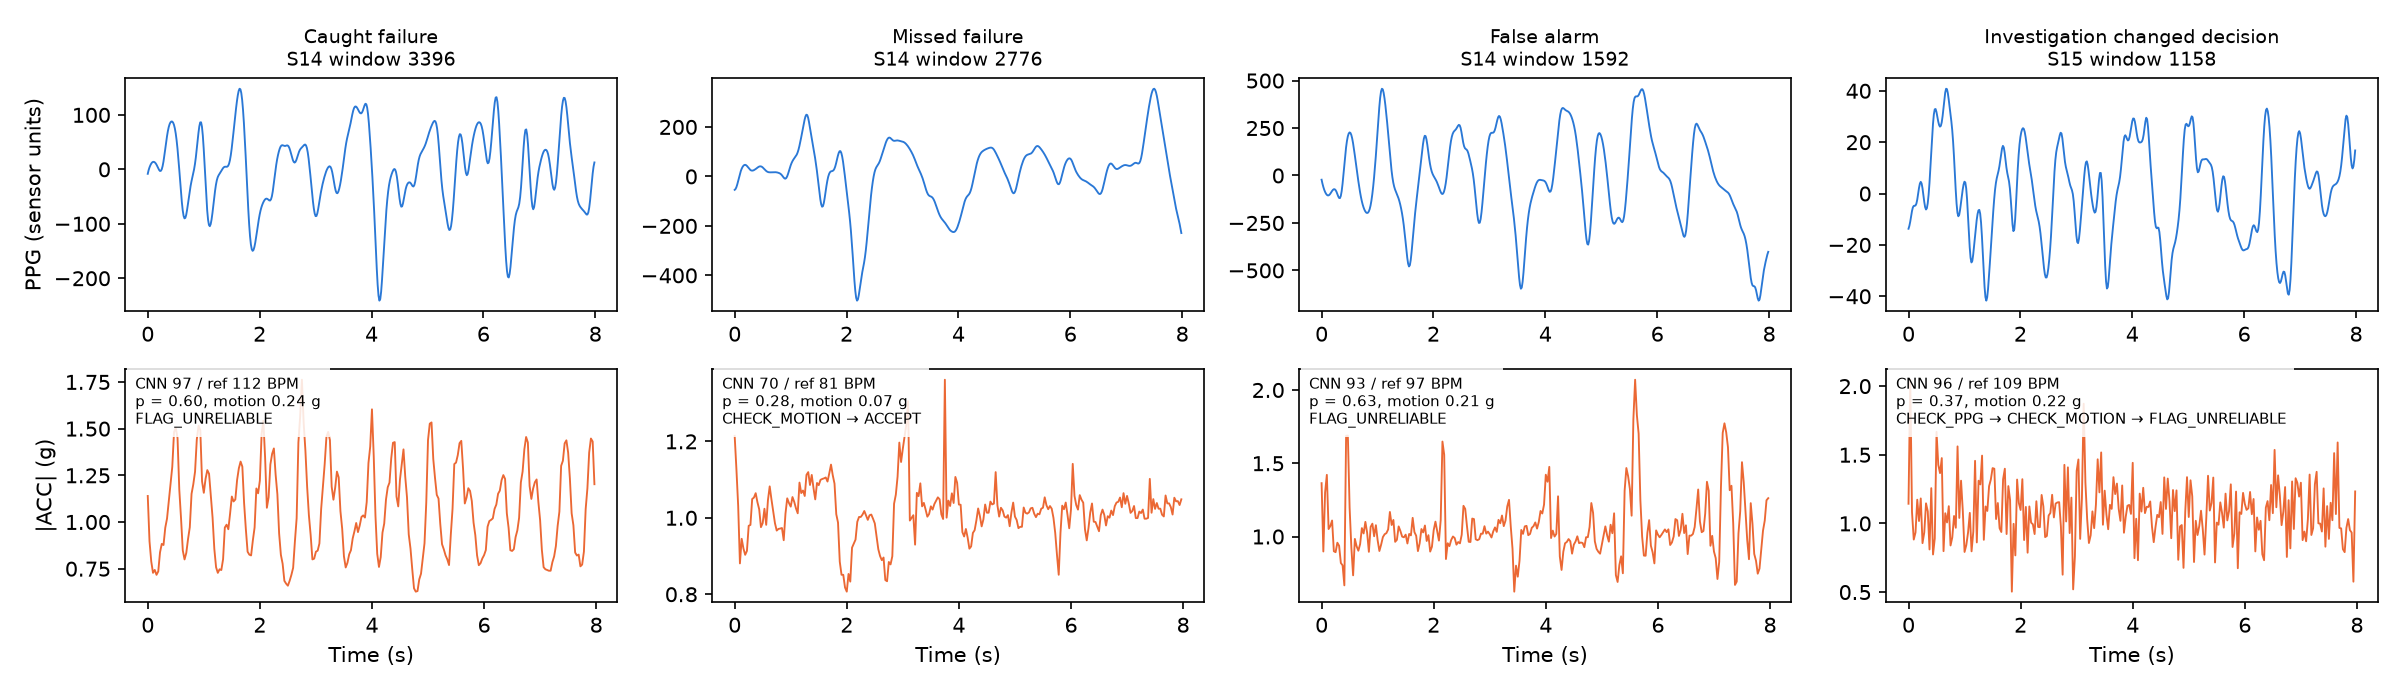

In [6]:
display(pd.read_csv(R / "d4_failure_cases/category_summary.csv").round(3))
display(Markdown("**Where investigations changed the decision relative to the probability-only rule (p ≥ 0.5)**"))
display(pd.read_csv(R / "d4_failure_cases/investigation_changes.csv").round(3))
display(Markdown("**Outcome by motion level**"))
display(pd.read_csv(R / "d4_failure_cases/category_by_motion.csv"))
display(Markdown("**Representative windows (chosen by rule: closest to each category's median)**"))
display(pd.read_csv(R / "d4_failure_cases/representative_examples.csv").round(2))
display(Image(str(R / "d4_failure_cases/representative_examples.png"), width=950))

## Phase 5: Exploratory usability feedback

The protocol, tasks, questionnaire and scoring script are in `docs/usability/` and `src/experiments/score_usability.py`. Sessions with 3–5 volunteers are run by the project author; results are reported as exploratory feedback only.

## Summary

| Analysis | Result |
|---|---|
| Motion-aware veto | Not supported: failed the out-of-participant and test criteria; it removes low-motion flags and cannot fix high-motion false alarms |
| Participant-wise | The agent has the highest recall for every participant; its gain over the fixed rule ranges from 6 to 33 recall points, and its false-positive rate is highest for S14 |
| Uncertainty | Recall gain over the fixed rule is +17.8 points [14.9, 20.7] for 7.6 more false-positive points [6.2, 9.0]; stable across block lengths |
| Failure cases | False alarms concentrate in moderate and high motion, and half of them are flagged without checks; within high motion the classifier is near chance (AUC 0.53) |